# Information

# 0. Setup
load required libs
specify paths

In [1]:
import qiime2 as q2
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import r2_score

In [2]:
data_dir = "../../data"

# 1. Data Import

In [3]:
meta = pd.read_csv(f"{data_dir}/metadata.tsv", sep="\t", index_col="sample-id")
meta.head()
meta.columns

Index(['collection_date', 'country', 'instrument', 'sample_number',
       'delivery_mode', 'host_sex', 'diet_milk', 'city', 'latitude',
       'longitude', 'urca_code', 'urca_description', 'host_id', 'host_age',
       'seq_depth', 'age_months'],
      dtype='object')

In [4]:
table = q2.Artifact.load(f"{data_dir}/../output/02_taxonomicclassification/feature-table.qza").view(pd.DataFrame)

# 2. MAZ (microbiota-by-age Z-score)

In [7]:
idx = table.index.intersection(meta.index)
X = table.loc[idx]                                  # same input as your baseline (counts)
y = meta.loc[idx, "host_age"].astype(float)
groups = meta.loc[idx, "host_id"]

# 1) out-of-fold predictions for all samples (infant-grouped)
rf = RandomForestRegressor(n_estimators=500, random_state=22, n_jobs=-1)
pred = cross_val_predict(rf, X, y, groups=groups, cv=GroupKFold(n_splits=5))
print("grouped-CV R2:", r2_score(y, pred))

# 2) residuals and MAZ (z-score within each age, all samples as reference)
df = meta.loc[idx, ["host_id", "host_age", "delivery_mode", "diet_milk"]].copy()
df["pred"] = pred
df["resid"] = df["pred"] - df["host_age"]
g = df.groupby("host_age")["resid"]
df["MAZ"] = (df["resid"] - g.transform("mean")) / g.transform("std")

# 4) mixed model, infant as random effect
d2 = df.dropna(subset=["MAZ", "delivery_mode", "diet_milk"])
m = smf.mixedlm("MAZ ~ C(delivery_mode) + C(diet_milk) + host_age", d2, groups=d2["host_id"]).fit()
print(m.summary())

grouped-CV R2: 0.7856564376506132
                Mixed Linear Model Regression Results
Model:                 MixedLM      Dependent Variable:      MAZ      
No. Observations:      143          Method:                  REML     
No. Groups:            38           Scale:                   0.8316   
Min. group size:       2            Log-Likelihood:          -201.3087
Max. group size:       5            Converged:               Yes      
Mean group size:       3.8                                            
----------------------------------------------------------------------
                            Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------------
Intercept                    0.056    0.193  0.288 0.773 -0.322  0.433
C(delivery_mode)[T.vaginal] -0.246    0.191 -1.284 0.199 -0.621  0.129
C(diet_milk)[T.mixed]        0.044    0.198  0.221 0.825 -0.344  0.431
host_age                     0.004    0.009  0.472 0.637 -0.

# 3. Visualization of MAZ

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, col in zip(axes, ["delivery_mode", "diet_milk"]):
    # one thin line per infant, coloured by group
    sns.lineplot(data=df.sort_values("host_age"), x="host_age", y="MAZ", hue=col,
                 units="host_id", estimator=None, lw=0.8, alpha=0.4, ax=ax)
    # group mean on top
    sns.lineplot(data=df, x="host_age", y="MAZ", hue=col, errorbar=None,
                 lw=3, marker="o", legend=False, ax=ax)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xticks(sorted(df["host_age"].unique()))
    ax.set_xlabel("host age (months)"); ax.set_ylabel("MAZ")
    ax.set_title(f"Infant MAZ trajectories by {col}")
plt.tight_layout()
plt.show()

backend: agg
df: (234, 7) | MAZ NaN: 0


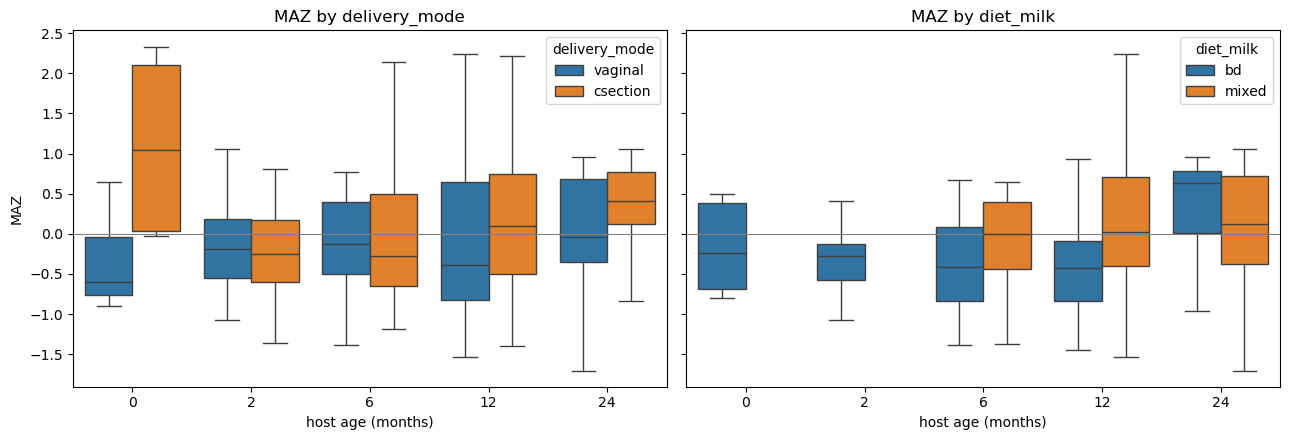

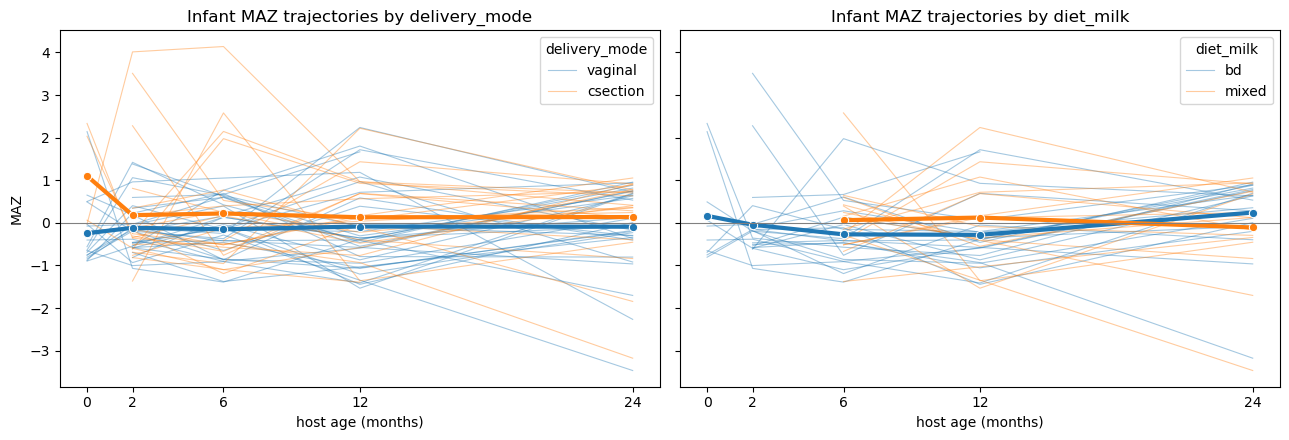

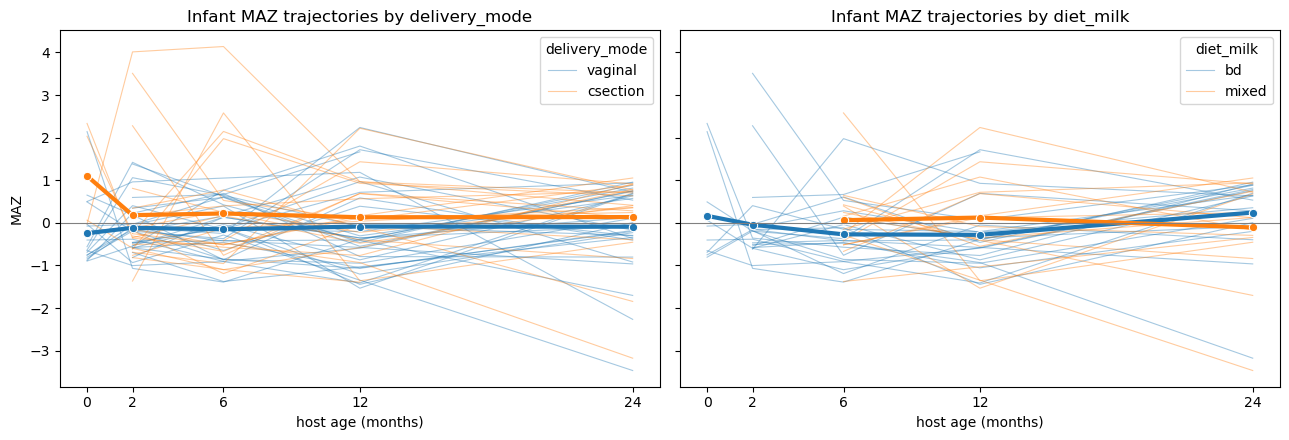

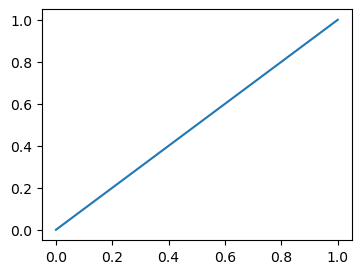

figures open: []


In [9]:
import matplotlib
print("backend:", matplotlib.get_backend())
print("df:", df.shape, "| MAZ NaN:", df["MAZ"].isna().sum())

%matplotlib inline
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(4, 3)); ax.plot([0, 1], [0, 1])
plt.show()
print("figures open:", plt.get_fignums())